In [1]:

import numpy as np 
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/datasets/bahaabashtawi/dataset-4h-ml/XAU_4h_data.csv


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def load_and_preprocess_data():
    df = pd.read_csv('XAU_4h_data.csv', sep=';')
    df = df.dropna().head(2000) 
    X = df[['Open']].values
    y = df['Close'].values
    
    
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)
    
   
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_poly)
    
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
    
    return X_scaled, y_scaled

Mini-batch GD with Momentum Final Cost: 0.009158250877453646
Mini-batch GD with Momentum Final Theta: [1.11303882 2.99905909 3.72067001]


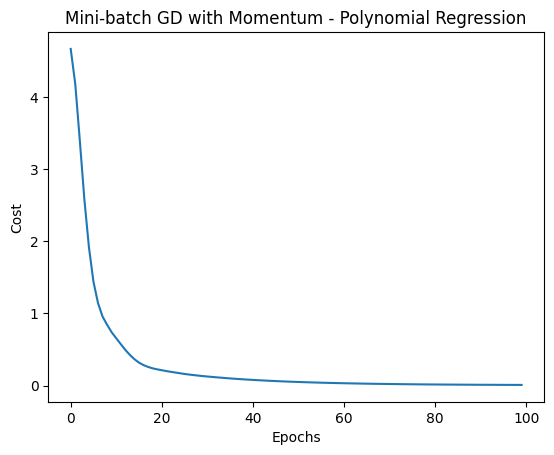

In [3]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)
m_samples = 150  

X_raw = 2 * np.random.rand(m_samples, 1) - 1
y_raw = 4 * (X_raw ** 2) + 3 * X_raw + 1 + 0.1 * np.random.randn(m_samples, 1)
y = y_raw.squeeze() 


X = np.c_[np.ones(m_samples), X_raw, X_raw**2]
m, n = X.shape


theta = np.zeros(n)
learning_rate = 0.01
gamma = 0.9  
v = np.zeros(n)
batch_size = 64
epochs = 100
costs = []


for epoch in range(epochs):
    permutation = np.random.permutation(m)
    X_shuffled = X[permutation]
    y_shuffled = y[permutation]
    
    epoch_cost = 0
    for i in range(0, m, batch_size):
        X_batch = X_shuffled[i:i+batch_size]
        y_batch = y_shuffled[i:i+batch_size]
        batch_m = X_batch.shape[0]
        
        predictions = np.dot(X_batch, theta)
        errors = predictions - y_batch
        epoch_cost += np.sum(errors ** 2)
        
        gradient = (1 / batch_m) * np.dot(X_batch.T, errors)
        
        
        v = gamma * v + learning_rate * gradient
        theta -= v
        
    costs.append(epoch_cost / (2 * m))

 
print("Mini-batch GD with Momentum Final Cost:", costs[-1])
print("Mini-batch GD with Momentum Final Theta:", theta)

 
plt.plot(costs)
plt.title("Mini-batch GD with Momentum - Polynomial Regression")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.savefig("minibatch_momentum_cost.png")
plt.show()